# Analyze TfR1 orthologs

In [1]:
# Imports
import os
import warnings
import altair as alt
import pandas as pd
import numpy as np
import matplotlib.colors
import seaborn as sns
import matplotlib.pyplot as plt
from pymsaviz import MsaViz 
from Bio import SeqIO, AlignIO

# Create color palette
def color_gradient_hex(start, end, n):
    """Color function from polyclonal"""
    cmap = matplotlib.colors.LinearSegmentedColormap.from_list(
            name="_", colors=[start, end], N=n
        )
    return [matplotlib.colors.rgb2hex(tup) for tup in cmap(list(range(0, n)))]

# Black to white color scale
gray_scale = color_gradient_hex("white", "#000000", n=11)

# Seaborn style settings
sns.set(rc={"figure.dpi":300, "savefig.dpi":300})
sns.set_style("ticks")

# Suppress warnings
warnings.simplefilter("ignore")

In [2]:
# File paths
human_TfR1 = "Data/human_TfR1_NM_003234.fasta"
C_callosus_TfR1 = "Data/C_callosus_TfR1_EU164540.fasta"
C_musculinus_TfR1_EU164541 = "Data/C_musculinus_TfR1_EU164541.fasta"

out_dir = "Results/"
msa_figure = "Results/TfR1_MSA.svg"

In [3]:
list_of_files = [
    human_TfR1,
    C_callosus_TfR1,
    C_musculinus_TfR1_EU164541,
]
all_TfR1_orthologs = "all_TfR1_orthologs.fasta"
alignment = "alignment.fasta"

# Concat fasta files
os.system(f"cat {' '.join(list_of_files)} > {all_TfR1_orthologs}")

# Align sequences
os.system(f"mafft --auto --quiet {all_TfR1_orthologs} > {alignment}")

0

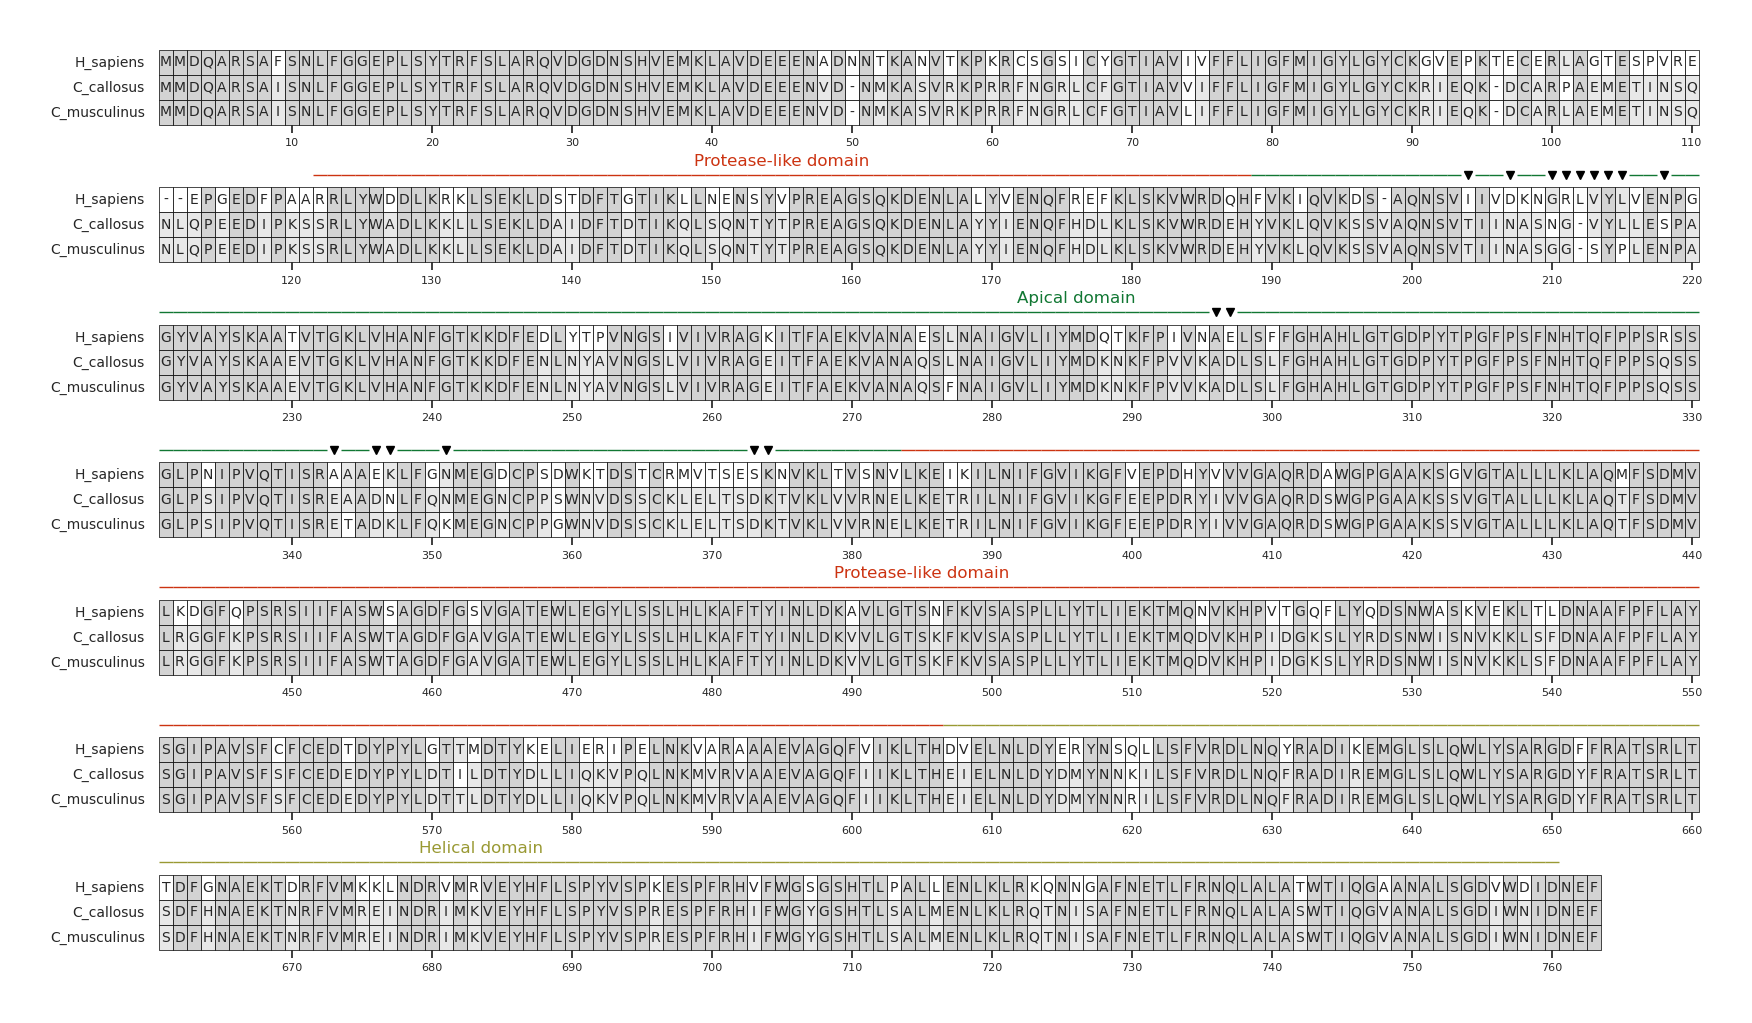

In [4]:
# Visualize alignment
mv = MsaViz(
    alignment, 
    color_scheme="Identity", 
    consensus_color="lightgrey",
    wrap_length=110, 
    show_grid=True, 
    show_consensus=False,
    consensus_size=1,
    wrap_space_size=2.5,
)

mv.set_plot_params(
    grid_color="black", 
    identity_color="lightgrey",
    y_unit_size=0.25
)

# From Aisen, 2004
mv.add_text_annotation(
    (122, 188), 
    "Protease-like domain", 
    text_color="#CC3311", 
    range_color="#CC3311", 
    text_size=12
)
mv.add_text_annotation(
    (384, 606), 
    "Protease-like domain", 
    text_color="#CC3311", 
    range_color="#CC3311", 
    text_size=12
)
mv.add_text_annotation(
    (189, 383), 
    "Apical domain", 
    text_color="#117733", 
    range_color="#117733", 
    text_size=12
)
mv.add_text_annotation(
    (607, 760), 
    "Helical domain", 
    text_color="#999933", 
    range_color="#999933", 
    text_size=12
)

# Add text annotations
# From Abraham et al 2010
positions_to_mark = [
    # Motif 1
    214, # Y211 -> 214 interacts w/ MACV 113
    
    # Motif 2
    351, # N348 -> 351 interacts w/ MACV 116
    374, # K371 -> 374 interacts w/ MACV 114
    373, # S370 -> 373 interacts w/ MACV 114
    
    # Motif 3
    213, # V210 -> 213 interacts w/ MACV 111, 228
    215, # L212 -> 215 interacts w/ MACV 226, 223
    204, # I201 -> 204
    
    # Motif 4
    218, # N215 -> 218 interacts w/ MACV 171
    296, # A293 -> 296
    297, # E294 -> 297 interacts w/ MACV 169
    343, # A340 -> 343
    346, # E343 -> 346 interacts w/ MACV 122
    347, # K344 -> 347 interacts w/ MACV 123
    
    # Motif 5
    207, # D204 -> 207
    # gaps in alignment causing issues in this area
    210, # 
    211, # 
    212, # L209 -> 213 interacts w/ MACV 97    
]
mv.add_markers(positions_to_mark, color="#000000")

fig = mv.plotfig()

# Make output dir if doesn't exist
if not os.path.exists(out_dir):
    os.mkdir(out_dir)

# Save fig
plt.savefig(msa_figure)

## Create pairwise identity heatmap

Code adapted from Ahn & Yu et al 2026

In [5]:
# Calculate pairwise amino acid identity

# Read the alignment
alignment = AlignIO.read(alignment, 'fasta')

# Extract names from sequence IDs
names = []
for record in alignment:
    name = record.id.split(" ")[0]
    names.append(name)

print(f"Found {len(names)} TfR1s: {', '.join(names)}")

# Calculate pairwise identity matrix
n_seqs = len(alignment)
results = []

for i in range(n_seqs):
    for j in range(n_seqs):
        seq1 = str(alignment[i].seq)
        seq2 = str(alignment[j].seq)
        
        if i == j:
            # Self-comparison
            results.append({
                'x': names[i],
                'y': names[j],
                'matches': np.nan,
                'alignable_residues': np.nan,
                'percent_identity': 100.0
            })
        else:
            # Count positions where both sequences have amino acids (not gaps)
            matches = 0
            alignable = 0
            
            for aa1, aa2 in zip(seq1, seq2):
                # Skip positions where either sequence has a gap
                if aa1 != '-' and aa2 != '-':
                    alignable += 1
                    if aa1 == aa2:
                        matches += 1
            
            pct_identity = (matches / alignable * 100) if alignable > 0 else 0
            
            results.append({
                'x': names[i],
                'y': names[j],
                'matches': matches,
                'alignable_residues': alignable,
                'percent_identity': pct_identity
            })

identity_df = pd.DataFrame(results)

print(f"\nCalculated {len(identity_df)} pairwise comparisons")
identity_df.head()

Found 3 TfR1s: H_sapiens, C_callosus, C_musculinus

Calculated 9 pairwise comparisons


,x,y,matches,alignable_residues,percent_identity
0,H_sapiens,H_sapiens,NaN,NaN,100.000000
1,H_sapiens,C_callosus,586.0,757.0,77.410832
2,H_sapiens,C_musculinus,586.0,757.0,77.410832
3,C_callosus,H_sapiens,586.0,757.0,77.410832
4,C_callosus,C_callosus,NaN,NaN,100.000000


In [6]:
def plot_identity_heatmap(df, title, width=100, height=100, order=None, highlight_pairs=None):
    """
    Plot a lower-triangle heatmap of sequence identity.
    
    Parameters:
    -----------
    df : DataFrame
        DataFrame with columns 'ha_x', 'ha_y', and 'percent_identity'
    title : str
        Title for the plot
    width : int
        Width of the plot
    height : int
        Height of the plot
    order : list, optional
        Order of HA subtypes for axes
    highlight_pairs : list of tuples, optional
        List of (ha_x, ha_y) pairs to highlight in red, e.g., [('H3', 'H5'), ('H3', 'H7')]
    """
    if order is None:
        order = sorted(df['x'].unique())

    # Filter to lower triangle only (excluding diagonal)
    # For lower triangle: index of ha_y > index of ha_x
    order_dict = {ha: i for i, ha in enumerate(order)}
    df_filtered = df[
        df.apply(lambda row: order_dict[row['y']] >= order_dict[row['x']], axis=1)
    ].copy()
    
    # Add highlight column if highlight_pairs is specified
    if highlight_pairs is not None:
        # Normalize pairs to ensure they're in the right order (lower triangle)
        normalized_pairs = set()
        for ha_x, ha_y in highlight_pairs:
            # Make sure we're using the lower triangle ordering
            if order_dict[ha_y] > order_dict[ha_x]:
                normalized_pairs.add((ha_x, ha_y))
            else:
                normalized_pairs.add((ha_y, ha_x))
        
        df_filtered['highlighted'] = df_filtered.apply(
            lambda row: (row['x'], row['y']) in normalized_pairs,
            axis=1
        )
    else:
        df_filtered['highlighted'] = False

    # Split data into highlighted and non-highlighted
    df_normal = df_filtered[~df_filtered['highlighted']]
    df_highlight = df_filtered[df_filtered['highlighted']]

    # Create base heatmap for non-highlighted cells
    heatmap_normal = alt.Chart(df_normal).mark_rect(
        opacity=0.95, stroke='black', strokeWidth=1
    ).encode(
        x=alt.X('x:N', title=None, axis=alt.Axis(labelAngle=-90), sort=order),
        y=alt.Y('y:N', title=None, sort=order),
        color=alt.Color(
            'percent_identity:Q',
            scale=alt.Scale(scheme='blues'),
            title=['Amino Acid', 'Identity (%)']
        )
    ).properties(
        width=width,
        height=height,
        title=alt.Title(title, anchor='middle')
    )
    
    # Create heatmap for highlighted cells (drawn on top)
    heatmap_highlight = alt.Chart(df_highlight).mark_rect(
        opacity=0.95, stroke='red', strokeWidth=3
    ).encode(
        x=alt.X('x:N', title=None, axis=alt.Axis(labelAngle=-90), sort=order),
        y=alt.Y('y:N', title=None, sort=order),
        color=alt.Color(
            'percent_identity:Q',
            scale=alt.Scale(scheme='blues'),
            title=['Amino Acid', 'Identity (%)']
        )
    )

    # Add text labels on the heatmap
    text = alt.Chart(df_filtered).mark_text(baseline='middle').encode(
        x=alt.X('x:N', sort=order),
        y=alt.Y('y:N', sort=order),
        text=alt.Text('percent_identity:Q', format='.0f'),
        color=alt.condition(
            alt.datum.percent_identity > 55,
            alt.value('white'),
            alt.value('black')
        )
    )

    # Layer them: normal cells first, then highlighted cells, then text on top
    chart = (heatmap_normal + heatmap_highlight + text)
    return chart

In [7]:
plot_identity_heatmap(
    identity_df, 
    title='', 
    width=75, 
    height=75, 
)

alt.LayerChart(...)